# 05 SRC Training and Selection

**Scientific question.** Can the exact selected model be restored identically?

**Learning objectives.** Read configurations, recreate forecasts and check stored scales and weights.

**Prerequisites.** Install the project requirements. Configure the data directory for raw-record checks. Portable evidence review also uses the existing run artifacts.

**Dataset and run.** Course gearbox at 3.2 kHz, the project’s designated training and held-out development records, and the explicit diagnostic or blind availability files where relevant.

**Execution.** This clean-kernel replay reads the evidence cited in each code cell. Use the explicit project pipeline for full fitting and the notebook build script for review replay. The companion guide contains notation, figures, and worked examples.

In [1]:
import hashlib
import json
import os
from pathlib import Path
import platform
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
get_ipython().run_line_magic("matplotlib", "inline")
from IPython.display import Image, display

hint = os.environ.get("SRC_PROJECT_DIR")
locations = [Path(hint).resolve()] if hint else [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in locations if (p / "src" / "src_gearbox").is_dir()), None)
if ROOT is None:
    raise RuntimeError("Open within the project or set SRC_PROJECT_DIR.")
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
DATA = Path(os.environ.get("SRC_DATA_DIR", ROOT / "data" / "raw"))
RESULTS = ROOT / "results"
START = 1792
N = 24000
pd.options.display.max_colwidth = 120
pd.options.display.width = 115
plt.rcParams.update({"figure.dpi": 105, "axes.grid": True, "grid.alpha": .18})

def table(relative):
    file = ROOT / relative
    if not file.is_file():
        print(f"NOT AVAILABLE YET · {relative}")
        return None
    return pd.read_csv(file)

def evidence(relative):
    file = ROOT / relative
    if not file.is_file():
        print(f"NOT AVAILABLE YET · {relative}")
        return {}
    return json.loads(file.read_text(encoding="utf-8"))

def show_fig(relative, width=780):
    file = ROOT / relative
    if file.is_file():
        display(Image(filename=str(file), width=width))
    else:
        print(f"NOT AVAILABLE YET · {relative}")

def forecast(relative):
    file = ROOT / relative
    if not file.is_file():
        print(f"NOT AVAILABLE YET · {relative}")
        return {}
    with np.load(file, allow_pickle=False) as source:
        arrays = {key: source[key] for key in source.files}
    np.testing.assert_array_equal(arrays["target_indices"], np.arange(START, N))
    assert np.isfinite(arrays["actual"]).all()
    return arrays

def align_forecasts(reference, *others):
    for other in others:
        for key in ("target_indices", "actual", "rpm", "time_s"):
            np.testing.assert_array_equal(reference[key], other[key])

def draw_forecast(bundle, keys, view=slice(5000, 5200)):
    if not bundle:
        return
    y, t = bundle["actual"], bundle["time_s"]
    fig, ax = plt.subplots(2, 1, figsize=(9.0, 4.0), sharex=True, layout="constrained")
    ax[0].plot(t[view], y[view], color="#141a26", lw=1.2, label="Measured")
    for key, label in keys.items():
        if key in bundle:
            pred = bundle[key]
            ax[0].plot(t[view], pred[view], lw=0.9, label=label)
            ax[1].plot(t[view], (y-pred)[view], lw=0.9, label=label)
    ax[0].legend(ncol=3, fontsize=8)
    ax[0].set_ylabel("Std. vibration")
    ax[1].set(ylabel="Std. residual", xlabel="Acquisition time (s)")
    plt.show()

print("Read-only evidence replay.", f"Python {platform.python_version()}",
      f"NumPy {np.__version__}. One-step observed history through t−1.")

Read-only evidence replay. Python 3.12.14 NumPy 2.5.5. One-step observed history through t−1.


### Configuration, weights, and a new record

Fixed and optimized banks share the one-step task but may differ in
physics and capacity. The base prediction is an affine readout of
normalized selected groups. An optional causal adapter adds a clipped,
exponentially weighted correction using earlier base errors. This notebook
reads existing chosen settings and reloads the actual checkpoint with
frozen feature ordering. For weights estimated on the measured course
train segment, recover its identity using the saved hash.

Companion Chapters 8, 12 and 15 distinguish the three residual roles,
feature-scaling fit rows, and portably serialized runtime state.

In [2]:
registry = evidence("checkpoints/src_registry.json")
items = registry.get("models", [])
if items:
    display(pd.DataFrame(items)[["model","display","history","feature_columns","parameters",
                                "fit_s","train_mse","checkpoint_bytes"]])
ref = [x for x in items if x["model"] == "primary_pi_src"]
if ref:
    primary = ref[0]
    display(pd.Series(primary["config"], name="Frozen setting").to_frame())
    checkpoint = ROOT / primary["checkpoint"]
    assert hashlib.sha256(checkpoint.read_bytes()).hexdigest() == primary["sha256"]

,model,display,history,feature_columns,parameters,fit_s,train_mse,checkpoint_bytes
0,primary_pi_src,PI-SRC (selected),1280,879,1456,4.265193,0.308688,32494
1,pi_src_pure_mse,PI-SRC (clean-MSE selection),1536,879,1456,4.293649,0.304222,32503
2,pi_src_compact,PI-SRC-Compact,512,545,834,1.351202,0.339541,20939
3,pi_src_optimized,PI-SRC-Optimized (uncorrected),512,879,1456,4.143201,0.308682,32492
4,src_linear,SRC-Linear,96,97,98,0.051612,0.438217,5787
5,src_polynomial,SRC-Polynomial,96,124,125,0.112779,0.437514,6738
6,src_speed,SRC-Speed,96,291,292,0.453577,0.395150,10957
7,src_physics_linear,SRC-Physics-Linear,512,627,916,1.319211,0.333358,23025
8,pi_src_fixed,PI-SRC-Fixed,512,636,637,1.106232,0.340473,21274
9,src_generic,src generic,96,335,336,0.444427,0.394208,12220


,Frozen setting
variant,PI-SRC-Corrected
lags,96
lag_history,192
lag_policy,consecutive
angular_steps,16
mesh_cycles,8
harmonics,"[37, 74, 148, 259]"
fixed_hz,[]
taus,"[8, 32, 128]"
memory,512


,columns,squared_norm
group,,
angle,128,0.089281
energy,1,0.000065
innovation,24,0.130025
intercept,1,0.000024
lag,96,0.148851
nonlinear_delay,19,0.000496
nonlinear_energy,14,0.000203
nonlinear_innovation,4,0.000088
nonlinear_oscillator,23,0.001071


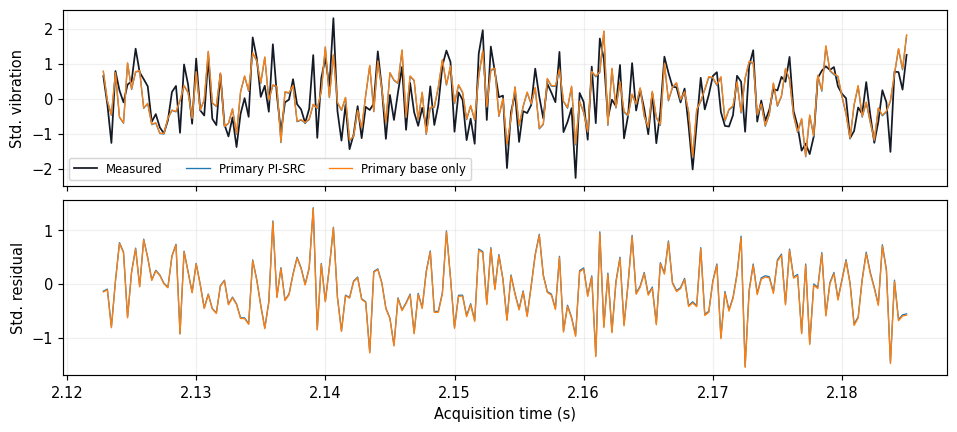

In [3]:
from src_gearbox.data import find_input, load_record
from src_gearbox.src_model import load_model

bundled = forecast("results/predictions/src_sigvalid.npz")
path = find_input(DATA, "sigvalid")
if ref and path and bundled:
    sample = load_record(path)
    final_model = load_model(checkpoint)
    from threadpoolctl import threadpool_limits
    with threadpool_limits(limits=1):
        yhat = final_model.predict(sample.x, sample.rpm, sample.fs)
    np.testing.assert_allclose(yhat[START:], bundled["primary_pi_src"], atol=1e-8, rtol=0)
    weights = pd.DataFrame(final_model.readout_features, columns=["term","group","weight"])
    display(weights.assign(w2=weights.weight**2).groupby("group").agg(
        columns=("term","count"), squared_norm=("w2","sum")))
draw_forecast(bundled, {"primary_pi_src":"Primary PI-SRC",
                         "pi_src_adapter_off":"Primary base only"})

### A miniature train and restore example

Fit a 12-lag readout to an illustrative noisy process before predicting
a second pseudo-record. Fit statistics come from the first pseudo-record.
The primary experiment fits the full training record using the
guarded search selection. This cell exercises the same model entry
points on synthetic arrays and writes only to a temporary directory.

In [4]:
from tempfile import TemporaryDirectory
from src_gearbox.src_model import Config, fit
from threadpoolctl import threadpool_limits

rng = np.random.default_rng(2026)
time_axis = np.arange(1800)/3200
rate = np.full(1800,140.)
signal = np.sin(2*np.pi*75*time_axis)+rng.normal(scale=.08,size=len(time_axis))
config = Config(variant="SRC-Linear",lags=12,ridge=.02,adapter_gain=0,
                pulse_preservation=0,augmentation=0)
with TemporaryDirectory() as folder, threadpool_limits(limits=1):
    model = fit(config,[(signal[:1100],rate[:1100])],3200)
    state = Path(folder)/"illustrative.npz"
    model.save(state)
    yhat = model.predict(signal[1100:],rate[1100:],3200)
    from_disk = load_model(state).predict(signal[1100:],rate[1100:],3200)
need = np.isfinite(yhat)
np.testing.assert_array_equal(yhat[need],from_disk[need])
print(f"Synthetic holdout MSE: {np.mean((signal[1100:][need]-yhat[need])**2):.5f}")

Synthetic holdout MSE: 0.00867


### Interpretation and limits

The reload check establishes reproducible numerical identity for the saved
model. Weight norms describe the fitted coordinate system and can reflect
collinearity rather than physical causation. For group usefulness, inspect
the guarded and matched development ablations.

Read the [Companion Guide](../docs/companion_guide.md) and the [Project README](../README.md).